In [1]:
from pathlib import Path

%cd ../..

d:\User Installed Folders\Master Thesis


In [ ]:
from stable_baselines3 import SAC

from Simulation.Auxilaries.io import load_env_ship
from Simulation.Auxilaries.sim_config import sim_config
from Agent.Observation.observation import build_observation
from Explanations.Lime.lime import LimeExplainer
from Explanations.Lime.lime_model import RunValueClass, StepValueClass
from Explanations.Lime.peragentcontroller import PerAgentController

angle_path = Path("Scenarios/Angular/0_degrees.json")
velo_path  = Path("Scenarios/Velocity/v_0.json")
model_path = Path("sac_ship_07_0_1.6m.zip")

model = SAC.load(model_path)

In [30]:
env, ship = load_env_ship(angle_path, sim_config)
pac = PerAgentController(sim_config, model)
pac.new_training_instance(pre_made_env=env, pre_made_ship=ship)
state = build_observation(pac, reduced=True)["state"]
pac.store_base_state()

Perturbation(ship_x=-0.76, ship_y=0.76, heading_cos=1.0, heading_sin=0.0, velocity=0.0, time_elapsed=0.0, end_x=0.7469332924566261, end_y=-0.7445798525798525)

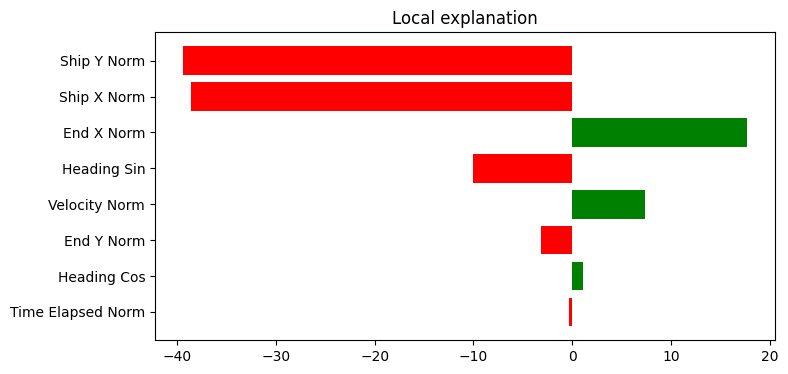

In [31]:
lime = LimeExplainer(pac)

stepcount_explanation = lime.get_explainer_instance(
    state,
    RunValueClass.REWARD_DELTA,
    num_samples=3000,
    discretize_continuous=False
)

_ = stepcount_explanation.as_pyplot_figure(figsize=(8, 4))

In [25]:
env, ship = load_env_ship(velo_path, sim_config)
pac = PerAgentController(sim_config, model)
pac.new_training_instance(pre_made_env=env, pre_made_ship=ship)
state = build_observation(pac, reduced=True)["state"]
pac.store_base_state()

Perturbation(ship_x=0.0, ship_y=-0.45999999999999996, heading_cos=6.123233995736766e-17, heading_sin=1.0, velocity=0.0, time_elapsed=0.0, end_x=0.00010465046281238344, end_y=-0.7497127681512294)

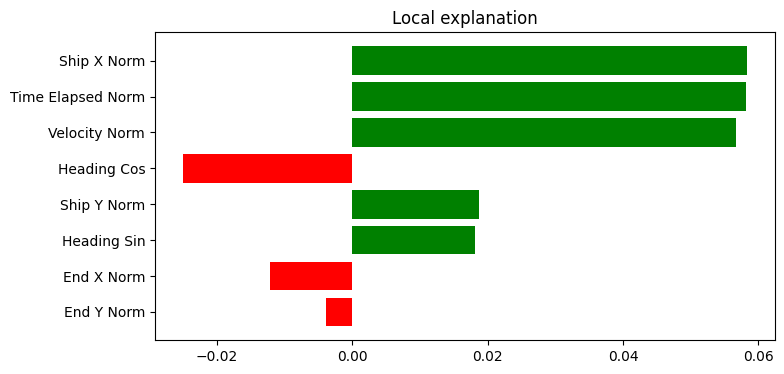

In [26]:
from Explanations.Lime.lime_model import StepValueClass
lime = LimeExplainer(pac)
stepcount_explanation = lime.get_explainer_instance(
    state,
    StepValueClass.THROTTLE,
    num_samples=10000,
    discretize_continuous=False
)

_ = stepcount_explanation.as_pyplot_figure(figsize=(8, 4))

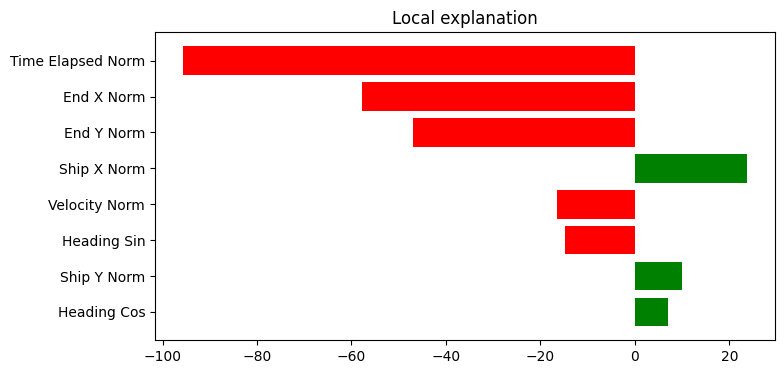

In [7]:
example_path = Path("Scenarios/Positional/base.json")
env, ship = load_env_ship(example_path, sim_config)
pac = PerAgentController(sim_config, model)
pac.new_training_instance(pre_made_env=env, pre_made_ship=ship)
state = build_observation(pac, reduced=True)["state"]
pac.store_base_state()

lime = LimeExplainer(pac)

stepcount_explanation = lime.get_explainer_instance(
    state,
    RunValueClass.STEPCOUNT,
    num_samples=1000,
    discretize_continuous=False
)

_ = stepcount_explanation.as_pyplot_figure(figsize=(8, 4))

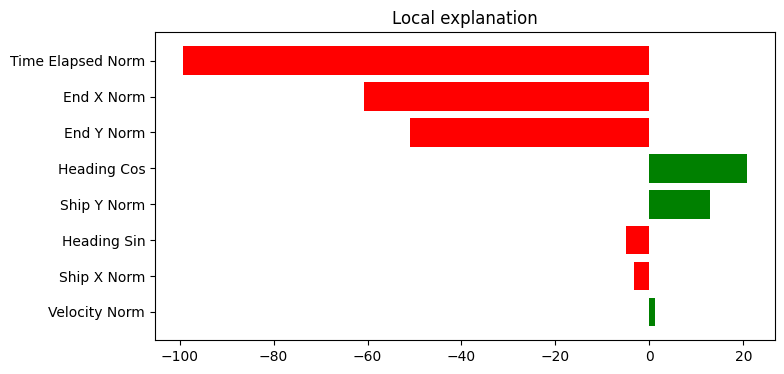

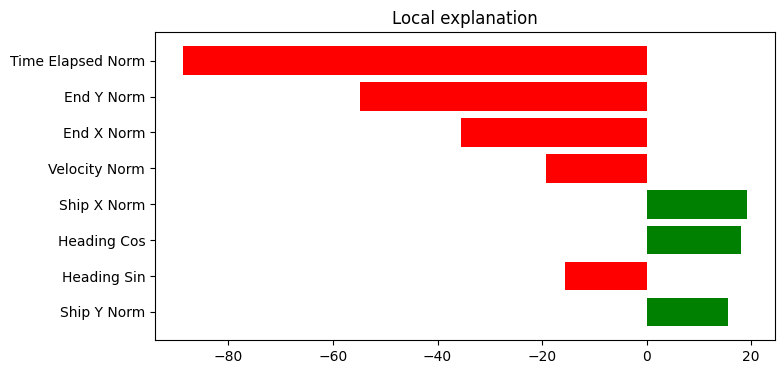

In [8]:
stepcount_explanation = lime.get_explainer_instance(
    state,
    RunValueClass.STEPCOUNT,
    num_samples=1000,
    discretize_continuous=False
)

_ = stepcount_explanation.as_pyplot_figure(figsize=(8, 4))

stepcount_explanation = lime.get_explainer_instance(
    state,
    RunValueClass.STEPCOUNT,
    num_samples=1000,
    discretize_continuous=False
)

_ = stepcount_explanation.as_pyplot_figure(figsize=(8, 4))